# Fase 7 — Robustez frente à IA generativa e explicabilidade


### O que este notebook faz

Confronta os três modelos com o conjunto sintético nas duas formas de texto — natural e lematizada — e explica o resultado por LIME. A separação importa: o corpus é distribuído lematizado, de modo que avaliar em texto natural mede descasamento de forma, não capacidade de detecção. Inclui o teste de truncamento, que isola o efeito do comprimento.

### Entradas

- `dados/sinteticas_processadas.csv`
- `dados/metricas_classicos.csv`
- `dados/metricas_bertimbau.csv`

### Saídas de dados

- `dados/deteccao_sinteticas.csv`
- `dados/metricas_consolidadas.csv`
- `dados/lime_termos.csv`
- `dados/truncamento.csv`
- `dados/curva_truncamento.csv`
- `dados/fatorial_forma_comprimento.csv`
- `dados/metricas_sinteticas_completas.csv`
- `dados/registro_execucoes.csv`

### Figuras geradas
- `figuras/fig_desempenho_geral.png` — acurácia dos três modelos no corpus original
- `figuras/fig_descasamento.png` — acurácia no corpus e detecção nas duas formas de texto
- `figuras/fig_lime_termos.png` — termos que mais pesam na decisão do BERTimbau
- `figuras/fig_truncamento.png` — detecção antes e depois de igualar o comprimento
- `figuras/fig_curva_truncamento.png` — detecção em função do comprimento do texto


## 1. Ambiente

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

BASE    = Path('/content/drive/MyDrive/TCC')
DADOS   = BASE / 'dados'
FIGURAS = BASE / 'figuras'
MODELOS = BASE / 'modelos'
for pasta in (DADOS, FIGURAS, MODELOS):
    pasta.mkdir(parents=True, exist_ok=True)

print('projeto :', BASE)
print('dados   :', DADOS)
print('figuras :', FIGURAS)
print('modelos :', MODELOS)


Mounted at /content/drive
projeto : /content/drive/MyDrive/TCC
dados   : /content/drive/MyDrive/TCC/dados
figuras : /content/drive/MyDrive/TCC/figuras
modelos : /content/drive/MyDrive/TCC/modelos


## 2. Padrão visual das figuras

Mesmo módulo das demais fases: a célula grava `estilo_sbc.py` e a seguinte o importa. O cabeçalho do módulo justifica cada decisão visual em relação ao template da SBC.

In [2]:
%%writefile /content/estilo_sbc.py
# -*- coding: utf-8 -*-
import io
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, MaxNLocator
from PIL import Image

AZUL    = '#1B4F72'
LARANJA = '#D55E00'
AMBAR   = '#E8B04B'
VERDE   = '#117733'
TEXTO   = '#1A1A1A'
SUAVE   = '#5F6B7A'
GRADE   = '#E4E7EA'
NEUTRO  = '#C3C9D0'

PALETA  = [AZUL, LARANJA, AMBAR, VERDE]

AZUL_TEXTO    = AZUL
LARANJA_TEXTO = '#A64A00'
AMBAR_TEXTO   = '#8A6410'
VERDE_TEXTO   = '#0E5C28'

_LEGIVEL = {AZUL: AZUL_TEXTO, LARANJA: LARANJA_TEXTO,
            AMBAR: AMBAR_TEXTO, VERDE: VERDE_TEXTO}

T_PEQUENO  = 8.0
T_CORPO    = 9.0
T_ROTULO   = 9.5
T_TITULO   = 10.5
T_DESTAQUE = 13.0


def legivel(cor):
    return _LEGIVEL.get(cor, cor)


CORES_MODELO = {
    'Regressao Logistica': AZUL,
    'Regressão Logística': AZUL,
    'Random Forest': LARANJA,
    'BERTimbau': AMBAR,
}
CORES_CLASSE = {'Verdadeira': AZUL, 'Falsa': LARANJA}

MAPA_FRIO = LinearSegmentedColormap.from_list('sbc_frio', ['#F1F4F5', AZUL])
MAPA_DIV  = LinearSegmentedColormap.from_list('sbc_div', [AZUL, '#FFFFFF', LARANJA])

CM = 1 / 2.54
LARGURA = 15 * CM
LARGURA_MEIA = 7.2 * CM

_instaladas = {f.name for f in mpl.font_manager.fontManager.ttflist}
FAMILIA = next((f for f in ('Inter', 'Source Sans 3', 'Lato', 'Open Sans',
                            'Liberation Sans', 'DejaVu Sans')
                if f in _instaladas), 'sans-serif')

mpl.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 400,
    'savefig.bbox': 'tight',
    'savefig.facecolor': 'white',
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',

    'font.family': FAMILIA,
    'font.size': T_CORPO,
    'axes.titlesize': T_TITULO,
    'axes.titleweight': 'bold',
    'axes.titlepad': 12,
    'axes.labelsize': T_CORPO,
    'axes.labelcolor': TEXTO,
    'axes.labelpad': 10,
    'xtick.labelsize': T_CORPO,
    'ytick.labelsize': T_CORPO,
    'legend.fontsize': T_CORPO,

    'text.color': TEXTO,
    'axes.edgecolor': '#B9BDC2',
    'axes.linewidth': 0.8,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.spines.left': False,

    'xtick.color': SUAVE,
    'ytick.color': SUAVE,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.major.size': 0,
    'ytick.major.size': 0,
    'xtick.major.pad': 5,
    'ytick.major.pad': 5,

    'grid.color': GRADE,
    'grid.linewidth': 0.8,
    'axes.grid': False,

    'legend.frameon': False,
    'legend.handlelength': 1.2,
    'legend.handleheight': 1.2,
    'legend.columnspacing': 2.2,
    'legend.borderpad': 0.1,
    'legend.labelspacing': 0.6,

    'axes.prop_cycle': mpl.cycler(color=PALETA),
    'lines.linewidth': 2.0,
    'lines.markersize': 6,
    'patch.linewidth': 0,
})


_destino = Path('.')


def destino(pasta):
    global _destino
    _destino = Path(pasta)
    _destino.mkdir(parents=True, exist_ok=True)
    return _destino


def salvar(fig, nome, largura_cm=15.0, dpi=400):
    caminho = _destino / (nome + '.png')
    if largura_cm is None:
        fig.savefig(caminho, dpi=dpi, bbox_inches='tight', facecolor='white')
        print('[figura]', caminho.name, '(sem normalizacao)')
        return caminho

    alvo = int(round(largura_cm / 2.54 * dpi))
    buf = io.BytesIO()
    fig.savefig(buf, format='png', dpi=dpi, bbox_inches='tight',
                facecolor='white')
    buf.seek(0)
    im = Image.open(buf).convert('RGB')
    nota = ''
    if im.width > alvo:
        fator = alvo / im.width
        im = im.resize((alvo, max(1, int(round(im.height * fator)))),
                       Image.LANCZOS)
        nota = '  (reduzida {:.1%})'.format(1 - fator)
    elif im.width < alvo:
        tela = Image.new('RGB', (alvo, im.height), 'white')
        tela.paste(im, ((alvo - im.width) // 2, 0))
        im = tela
        nota = '  (margem branca completada)'
    im.save(caminho, dpi=(dpi, dpi))
    print('[figura] {:<30} {:.1f} x {:.1f} cm{}'
          .format(caminho.name, largura_cm, im.height / dpi * 2.54, nota))
    return caminho


def br(texto):
    return str(texto).replace(',', '\u0000').replace('.', ',').replace('\u0000', '.')


def pct(valor, dec=1):
    return br(('{:.' + str(dec) + 'f}').format(100 * valor)) + '%'


def mil(valor, dec=0):
    return br(('{:,.' + str(dec) + 'f}').format(valor))


def grade_y(ax, atras=True):
    ax.grid(axis='y', color=GRADE, linewidth=0.8)
    ax.grid(axis='x', visible=False)
    ax.set_axisbelow(atras)
    return ax


def grade_x(ax, atras=True):
    ax.grid(axis='x', color=GRADE, linewidth=0.8)
    ax.grid(axis='y', visible=False)
    ax.set_axisbelow(atras)
    return ax


def sem_grade(ax):
    ax.grid(False)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.set_xticks([])
    ax.set_yticks([])
    return ax


def eixo_percentual(ax, eixo='y', decimais=0):
    f = FuncFormatter(lambda v, _: pct(v, decimais))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def eixo_decimal(ax, eixo='y', decimais=2):
    f = FuncFormatter(
        lambda v, _: br(('{:,.' + str(decimais) + 'f}').format(v)))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def escala_percentual(ax, maximo=1.0, folga_topo=0.20, passo=0.2, decimais=0):
    import numpy as _np
    ax.set_ylim(0, maximo * (1 + folga_topo))
    ax.set_yticks(_np.round(_np.arange(0, maximo + 1e-9, passo), 10))
    eixo_percentual(ax, 'y', decimais)
    return ax


def eixo_milhar(ax, eixo='y'):
    f = FuncFormatter(lambda v, _: mil(v))
    (ax.yaxis if eixo == 'y' else ax.xaxis).set_major_formatter(f)
    return ax


def rotular(ax, barras, fmt='{:.1%}', dy=5, tam=T_ROTULO, peso='bold', cor=None):
    for b in barras:
        v = b.get_height()
        ax.annotate(br(fmt.format(v)),
                    xy=(b.get_x() + b.get_width() / 2, v),
                    xytext=(0, dy), textcoords='offset points',
                    ha='center', va='bottom',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def rotular_h(ax, barras, fmt='{:.1%}', dx=6, tam=T_ROTULO, peso='bold', cor=None):
    for b in barras:
        v = b.get_width()
        ax.annotate(br(fmt.format(v)),
                    xy=(v, b.get_y() + b.get_height() / 2),
                    xytext=(dx, 0), textcoords='offset points',
                    ha='left', va='center',
                    fontsize=tam, fontweight=peso,
                    color=cor or TEXTO)
    return ax


def encolher_para_caber(ax, textos, largura_dados, tamanho, minimo=6.5,
                        passo=0.2):

    fig = ax.figure
    fig.canvas.draw()
    renderizador = fig.canvas.get_renderer()
    base = ax.transData.transform((0, 0))[0]
    limite = ax.transData.transform((largura_dados, 0))[0] - base
    while tamanho > minimo:
        maior = max(t.get_window_extent(renderer=renderizador).width
                    for t in textos)
        if maior <= limite:
            break
        tamanho -= passo
        for t in textos:
            t.set_fontsize(tamanho)
    return tamanho


def legenda_abaixo(ax, ncols=2, afastamento=None, **kwargs):
    altura_pt = (ax.get_position().height * ax.figure.get_figheight() * 72) or 1
    if afastamento is None:
        afastamento = -(44 if ax.get_xlabel() else 24) / altura_pt
    return ax.legend(loc='upper center', ncols=ncols,
                     bbox_to_anchor=(0.5, afastamento),
                     fontsize=T_CORPO, **kwargs)


def legenda_manual(ax, itens, ncols=None, **kwargs):
    from matplotlib.patches import Patch
    marcas = [Patch(facecolor=cor, label=rotulo) for rotulo, cor in itens]
    return legenda_abaixo(ax, ncols=ncols or len(itens), handles=marcas,
                          **kwargs)


def titulo(ax, principal, apoio=None):
    linhas_apoio = apoio.count('\n') + 1 if apoio else 0
    ax.set_title(principal, loc='left',
                 pad=(25 + 12 * (linhas_apoio - 1)) if apoio else 10)
    if apoio:
        ax.annotate(apoio, xy=(0, 1), xycoords='axes fraction',
                    xytext=(0, 7), textcoords='offset points',
                    ha='left', va='bottom', fontsize=T_CORPO, color=SUAVE)
    return ax


def espacar(valores, minimo):
    import numpy as _np
    valores = _np.asarray(valores, dtype=float)
    pos = valores.copy()
    ordem = _np.argsort(valores)
    for k in range(1, len(ordem)):
        anterior, atual = ordem[k - 1], ordem[k]
        if pos[atual] - pos[anterior] < minimo:
            pos[atual] = pos[anterior] + minimo
    deslocamento = pos[ordem].mean() - valores[ordem].mean()
    return pos - deslocamento


def folga(ax, eixo='y', fator=0.14):
    if eixo == 'y':
        lo, hi = ax.get_ylim()
        ax.set_ylim(lo, hi + (hi - lo) * fator)
    else:
        lo, hi = ax.get_xlim()
        ax.set_xlim(lo, hi + (hi - lo) * fator)
    return ax


def painel_confusao(ax, matriz, titulo_painel, rotulos=('Verdadeira', 'Falsa'),
                    destaque=None):
    import numpy as np
    matriz = np.asarray(matriz, dtype=float)
    total = matriz.sum()
    ax.imshow(matriz / matriz.max(), cmap=MAPA_FRIO, vmin=0, vmax=1.15)
    for i in range(matriz.shape[0]):
        for j in range(matriz.shape[1]):
            v = matriz[i, j]
            claro = (v / matriz.max()) > 0.55
            ax.text(j, i - 0.10, mil(v),
                    ha='center', va='center', fontsize=T_DESTAQUE,
                    fontweight='bold',
                    color='white' if claro else TEXTO)
            ax.text(j, i + 0.22, pct(v / total, 1),
                    ha='center', va='center', fontsize=T_PEQUENO,
                    color='#E8EEF0' if claro else SUAVE)
    ax.set_xticks([0, 1], ['Predita\n' + rotulos[0], 'Predita\n' + rotulos[1]])
    ax.set_yticks([0, 1], ['Real\n' + rotulos[0], 'Real\n' + rotulos[1]])
    ax.set_title(titulo_painel, loc='center', pad=10,
                 color=legivel(destaque) if destaque else TEXTO)
    for lado in ('top', 'right', 'left', 'bottom'):
        ax.spines[lado].set_visible(False)
    ax.tick_params(length=0)
    ax.grid(False)
    return ax


def barras_pareadas(ax, categorias, series, fmt='{:.1%}', largura_grupo=0.78,
                    rotulo=True):
    import numpy as np
    x = np.arange(len(categorias))
    n = len(series)
    larg = largura_grupo / n
    for k, (nome, valores, cor) in enumerate(series):
        desloc = (k - (n - 1) / 2) * larg
        b = ax.bar(x + desloc, valores, larg * 0.92, label=nome, color=cor)
        if rotulo:
            rotular(ax, b, fmt=fmt, tam=T_PEQUENO)
    ax.set_xticks(x, categorias)
    grade_y(ax)
    return ax


print('estilo_sbc carregado  |  paleta', AZUL, LARANJA, AMBAR)


Writing /content/estilo_sbc.py


In [3]:
import shutil, sys
shutil.copy('/content/estilo_sbc.py', BASE / 'estilo_sbc.py')
sys.path.insert(0, '/content')

from estilo_sbc import *
destino(FIGURAS)

import numpy as np
import pandas as pd


estilo_sbc carregado  |  paleta #1B4F72 #D55E00 #E8B04B


## 3. Localizadores de arquivos e colunas

In [4]:
def arquivo(*nomes):
    tentados = []
    for nome in nomes:
        for pasta in (DADOS, BASE):
            alvo = pasta / nome
            tentados.append(str(alvo))
            if alvo.exists():
                return alvo
    raise FileNotFoundError(
        'Nenhum destes arquivos foi encontrado:\n  ' + '\n  '.join(tentados))


def existe(*nomes):
    try:
        return arquivo(*nomes)
    except FileNotFoundError:
        return None


def coluna(df, *candidatos, obrigatoria=True):
    mapa = {c.strip().lower(): c for c in df.columns}
    for cand in candidatos:
        if cand.strip().lower() in mapa:
            return mapa[cand.strip().lower()]
    for cand in candidatos:
        chave = cand.strip().lower()
        for norm, orig in mapa.items():
            if chave in norm:
                return orig
    if obrigatoria:
        raise KeyError('Nenhuma destas colunas existe: ' + ', '.join(candidatos)
                       + '\nDisponiveis: ' + ', '.join(map(str, df.columns)))
    return None


def csvs_do_projeto():
    achados = []
    for caminho in sorted(BASE.rglob('*.csv')):
        try:
            cabecalho = list(pd.read_csv(caminho, nrows=0).columns)
            with open(caminho, encoding='utf-8', errors='ignore') as fh:
                linhas = max(sum(1 for _ in fh) - 1, 0)
        except Exception as erro:
            cabecalho, linhas = ['<ilegível: {}>'.format(erro)], -1
        achados.append((caminho, linhas, cabecalho))
    return achados


def listar_csvs():
    achados = csvs_do_projeto()
    if not achados:
        print('nenhum CSV encontrado em', BASE)
        return
    for caminho, linhas, colunas in achados:
        print('{:<44} {:>7} linhas   {}'.format(
            str(caminho.relative_to(BASE)), linhas,
            ', '.join(map(str, colunas))[:88]))


def procurar_csv(*pistas_de_coluna, nomes=()):
    if nomes:
        alvo = existe(*nomes)
        if alvo is not None:
            return alvo
    candidatos = []
    for caminho, linhas, colunas in csvs_do_projeto():
        normalizadas = {str(c).strip().lower() for c in colunas}
        if any(any(pista in c for c in normalizadas) for pista in pistas_de_coluna):
            candidatos.append((linhas, caminho))
    if candidatos:
        candidatos.sort(reverse=True)
        escolhido = candidatos[0][1]
        print('localizado pelo conteúdo:', escolhido.relative_to(BASE))
        if len(candidatos) > 1:
            print('outros compatíveis:',
                  [str(c.relative_to(BASE)) for _, c in candidatos[1:]])
        return escolhido
    print('Nenhum CSV com coluna parecida com', pistas_de_coluna, 'foi encontrado.')
    print('Nomes procurados:', nomes or '(nenhum)')
    print('\nCSVs disponíveis em', BASE, ':')
    listar_csvs()
    raise FileNotFoundError(
        'Veja o inventário acima e renomeie o arquivo certo, ou gere-o de novo.')


def modelos_disponiveis():
    import datetime as _dt
    import json as _json
    achados = []
    for config in sorted(BASE.rglob('config.json')):
        pasta = config.parent
        if not (pasta / 'model.safetensors').exists() \
                and not (pasta / 'pytorch_model.bin').exists():
            continue
        marca = pasta / 'convencao_rotulo.json'
        convencao = None
        if marca.exists():
            try:
                convencao = _json.loads(marca.read_text(encoding='utf-8'))
            except Exception:
                convencao = {'erro': 'json ilegivel'}
        achados.append((pasta,
                        _dt.datetime.fromtimestamp(config.stat().st_mtime),
                        convencao))
    return sorted(achados, key=lambda t: t[1], reverse=True)


def listar_modelos():
    achados = modelos_disponiveis()
    if not achados:
        print('nenhum modelo encontrado em', BASE)
        return
    for pasta, quando, convencao in achados:
        print('{:<46} {}  {}'.format(
            str(pasta.relative_to(BASE)), quando.strftime('%d/%m %H:%M'),
            'rótulo 1 = ' + convencao.get('1', '?') if convencao
            else 'SEM convenção declarada'))


def achar_modelo(convencao_exigida='Falsa'):
    disponiveis = [t for t in modelos_disponiveis()
                   if 'checkpoint' not in t[0].name]
    if not disponiveis:
        return None

    corretos = [t for t in disponiveis
                if t[2] and t[2].get('1') == convencao_exigida]
    if corretos:
        return str(corretos[0][0])

    print('AVISO: nenhum modelo declara a convenção "rótulo 1 =',
          convencao_exigida, '". Usando o mais recente; confira a acurácia.')
    listar_modelos()
    return str(disponiveis[0][0])


_NLP = None


def motor_lema():
    global _NLP
    if _NLP is None:
        import spacy
        try:
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
        except OSError:
            import subprocess, sys
            subprocess.run([sys.executable, '-m', 'spacy', 'download',
                            'pt_core_news_sm'], check=True)
            _NLP = spacy.load('pt_core_news_sm', disable=['parser', 'ner'])
    return _NLP


def lematizar(textos, lote=32):
    nlp = motor_lema()
    return [' '.join(t.lemma_ for t in doc)
            for doc in nlp.pipe(list(textos), batch_size=lote)]


def taxa_de_lema(textos, limite=400):
    nlp = motor_lema()
    iguais = total = 0
    for doc in nlp.pipe(list(textos)[:limite], batch_size=32):
        for t in doc:
            if t.is_alpha and len(t.text) > 2:
                total += 1
                iguais += t.text.lower() == t.lemma_.lower()
    return iguais / total if total else float('nan')


## 4. Taxas de detecção nas duas formas

As taxas são recalculadas aqui, com os modelos desta execução. Ler um CSV de execução anterior misturaria modelos treinados sob outro formato de entrada numa tabela só.

Cada conjunto é avaliado duas vezes. Em **texto natural**, que é o que uma aplicação receberia de um usuário. E em **texto lematizado**, que é a forma em que o corpus de treino foi distribuído. A diferença entre as duas é o custo do descasamento, e só a segunda mede detecção.

Todos os textos são falsos por construção, então a taxa de detecção é a proporção classificada como falsa — `predito == 1`, pela convenção normalizada na Fase 1.

In [5]:
import joblib, torch
from transformers import AutoTokenizer, AutoModelForSequenceClassification

sint = pd.read_csv(procurar_csv(
    'texto_lematizado', 'texto_sintetico',
    nomes=('sinteticas_processadas.csv',)))
if 'rotulo' not in sint.columns:
    sint['rotulo'] = 1

falsas_sint = sint[sint['rotulo'] == 1]
natural = falsas_sint['texto_sintetico'].fillna('').astype(str).tolist()
lematizado = falsas_sint['texto_lematizado'].fillna('').astype(str).tolist()
print('notícias sintéticas: {} falsas, {} verdadeiras'.format(
    len(falsas_sint), int((sint['rotulo'] == 0).sum())))

vetor_det = joblib.load(MODELOS / 'tfidf.joblib')
lr_det = joblib.load(MODELOS / 'regressao_logistica.joblib')
rf_det = joblib.load(MODELOS / 'random_forest.joblib')

caminho_det = achar_modelo()
tok_det = AutoTokenizer.from_pretrained(caminho_det)
bert_det = AutoModelForSequenceClassification.from_pretrained(caminho_det).eval()
disp_det = 'cuda' if torch.cuda.is_available() else 'cpu'
bert_det.to(disp_det)


@torch.no_grad()
def prever_bert(textos, lote=64):
    saida = []
    for i in range(0, len(textos), lote):
        ent = tok_det(textos[i:i + lote], truncation=True, max_length=256,
                      padding=True, return_tensors='pt').to(disp_det)
        saida.append(bert_det(**ent).logits.argmax(-1).cpu().numpy())
    return np.concatenate(saida)


def taxas_de_deteccao(textos):
    """Proporção classificada como falsa. Rótulo 1 = falsa (Fase 1)."""
    if not callable(getattr(bert_det, '__call__', None)):
        raise TypeError('bert_det deixou de ser o modelo. Alguma célula '
                        'sobrescreveu o nome: rode a seção 4 de novo.')
    X = vetor_det.transform(textos)
    return {'Regressão Logística': float((lr_det.predict(X) == 1).mean()),
            'Random Forest': float((rf_det.predict(X) == 1).mean()),
            'BERTimbau': float((prever_bert(textos) == 1).mean())}


deteccao = pd.DataFrame({'natural': taxas_de_deteccao(natural),
                         'lematizado': taxas_de_deteccao(lematizado)})
deteccao['custo_descasamento_pp'] = 100 * (deteccao['natural']
                                           - deteccao['lematizado'])
deteccao.to_csv(DADOS / 'deteccao_sinteticas.csv')
print()
print(deteccao.round(4).to_string())

import json as _json
marca = Path(caminho_det) / 'convencao_rotulo.json'
info = _json.loads(marca.read_text(encoding='utf-8')) if marca.exists() else {}
treinado_em = info.get('treinado_em', 'desconhecido')
mb = pd.read_csv(arquivo('metricas_bertimbau.csv'), index_col=0)
registro_arq = DADOS / 'registro_execucoes.csv'
registro = pd.read_csv(registro_arq) if registro_arq.exists() else pd.DataFrame()
if registro.empty or treinado_em not in set(registro.get('treinado_em', [])):
    nova = pd.DataFrame([{
        'execucao': 'automática', 'treinado_em': treinado_em,
        'selecao_epoca': info.get('epoca_escolhida_por', 'não registrada'),
        'n_treino': info.get('n_treino'),
        'acuracia_teste': float(mb['acuracia'].iloc[0]),
        'erros_teste': int(mb['erros'].iloc[0]),
        'deteccao_natural': float(deteccao.loc['BERTimbau', 'natural']),
        'deteccao_lematizada': float(deteccao.loc['BERTimbau', 'lematizado']),
        'origem': 'Fase 7'}])
    registro = pd.concat([registro, nova], ignore_index=True)
    registro.to_csv(registro_arq, index=False)
    print('\nexecução registrada em dados/registro_execucoes.csv')
else:
    print('\nmodelo de', treinado_em, 'já constava do registro de execuções')
print(registro[['execucao', 'selecao_epoca', 'acuracia_teste',
                'deteccao_natural', 'deteccao_lematizada']].to_string(index=False))


notícias sintéticas: 147 falsas, 147 verdadeiras


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


                     natural  lematizado  custo_descasamento_pp
Regressão Logística   0.6531      0.7959               -14.2857
Random Forest         0.4558      0.4898                -3.4014
BERTimbau             0.0136      0.9932               -97.9592

modelo de 2026-10-17T17:14:29 já constava do registro de execuções
  execucao           selecao_epoca  acuracia_teste  deteccao_natural  deteccao_lematizada
         A f1 no conjunto de teste        0.976500          0.000000             1.000000
         B f1 no conjunto de teste        0.975200          0.000000             1.000000
         C         f1 de validação        0.976500          0.224500             1.000000
automática         f1 de validação        0.972701          0.013605             0.993197


### 4.1. Avaliação com as duas classes

A taxa de detecção sozinha é revocação: um modelo que respondesse "falsa" a tudo marcaria 100%. Se o conjunto sintético tiver também notícias verdadeiras, esta célula calcula o quadro completo — especificidade, precisão, F1 e acurácia balanceada — com intervalos por bootstrap, que dizem quanto da diferença entre modelos cabe dentro do tamanho da amostra.

In [6]:
from sklearn.metrics import confusion_matrix

y_sint = sint['rotulo'].to_numpy()
duas_classes = len(np.unique(y_sint)) == 2

if not duas_classes:
    print('Conjunto com uma classe só ({} itens, todos {}).'
          .format(len(y_sint), 'falsos' if y_sint[0] == 1 else 'verdadeiros'))
    print('A métrica possível é a revocação da seção anterior. Para medir '
          'falso alarme, regere o conjunto na Fase 6 com as duas classes.')
else:
    def prever(textos):
        X = vetor_det.transform(textos)
        return {'Regressão Logística': lr_det.predict(X),
                'Random Forest': rf_det.predict(X),
                'BERTimbau': prever_bert(textos)}

    def quadro(y, pred):
        mc = confusion_matrix(y, pred, labels=[0, 1])
        vn, fp, fn, vp = mc.ravel()
        rev = vp / (vp + fn) if vp + fn else np.nan        # detecta falsa
        esp = vn / (vn + fp) if vn + fp else np.nan        # poupa verdadeira
        prec = vp / (vp + fp) if vp + fp else np.nan
        return {'revocacao': rev, 'especificidade': esp, 'precisao': prec,
                'f1': 2 * prec * rev / (prec + rev) if prec + rev else np.nan,
                'acuracia_balanceada': (rev + esp) / 2,
                'falso_alarme': 1 - esp}

    def ic_bootstrap(y, pred, n=2000, semente=42):
        rng = np.random.default_rng(semente)
        amostras = [quadro(y[i], pred[i])['acuracia_balanceada']
                    for i in (rng.integers(0, len(y), len(y)) for _ in range(n))]
        return np.percentile(amostras, [2.5, 97.5])

    todas_nat = sint['texto_sintetico'].fillna('').astype(str).tolist()
    todas_lem = sint['texto_lematizado'].fillna('').astype(str).tolist()

    linhas = []
    for forma, textos in (('natural', todas_nat), ('lematizado', todas_lem)):
        for nome, pred in prever(textos).items():
            m = quadro(y_sint, pred)
            baixo, alto = ic_bootstrap(y_sint, pred)
            m.update({'modelo': nome, 'forma': forma,
                      'ic95_baixo': baixo, 'ic95_alto': alto})
            linhas.append(m)

    completo = pd.DataFrame(linhas).set_index(['forma', 'modelo'])
    completo.to_csv(DADOS / 'metricas_sinteticas_completas.csv')
    print(completo.round(4).to_string())
    print('\nIC de 95% por bootstrap sobre a acurácia balanceada, '
          '2.000 reamostragens. n = {} notícias ({} falsas, {} verdadeiras).'
          .format(len(y_sint), int((y_sint == 1).sum()), int((y_sint == 0).sum())))


                                revocacao  especificidade  precisao      f1  acuracia_balanceada  falso_alarme  ic95_baixo  ic95_alto
forma      modelo                                                                                                                    
natural    Regressão Logística     0.6531          0.9660    0.9505  0.7742               0.8095        0.0340      0.7675     0.8493
           Random Forest           0.4558          0.8707    0.7791  0.5751               0.6633        0.1293      0.6164     0.7134
           BERTimbau               0.0136          1.0000    1.0000  0.0268               0.5068        0.0000      0.5000     0.5177
lematizado Regressão Logística     0.7959          0.9864    0.9832  0.8797               0.8912        0.0136      0.8562     0.9235
           Random Forest           0.4898          0.9048    0.8372  0.6180               0.6973        0.0952      0.6515     0.7446
           BERTimbau               0.9932          0.9320    0

## 5. Consolidação das métricas

Uma tabela reúne o desempenho no corpus e a detecção nas duas formas. É dela que saem as figuras seguintes e as tabelas do artigo, de modo que nenhum número exista em dois lugares.

A coluna `queda_pp` compara a acurácia no corpus com a detecção **de forma casada** — é a medida de robustez que o artigo reporta. Comparar com a coluna natural somaria dois efeitos distintos.

In [7]:
classicos = pd.read_csv(arquivo('metricas_classicos.csv'), index_col=0)
metricas_bert = pd.read_csv(arquivo('metricas_bertimbau.csv'), index_col=0)
consolidado = pd.concat([classicos, metricas_bert])
consolidado['deteccao_natural'] = deteccao['natural']
consolidado['deteccao_lematizada'] = deteccao['lematizado']
consolidado['custo_descasamento_pp'] = deteccao['custo_descasamento_pp']
consolidado['queda_pp'] = 100 * (consolidado['acuracia']
                                 - consolidado['deteccao_lematizada'])
consolidado = consolidado.loc[['Regressão Logística', 'Random Forest', 'BERTimbau']]
consolidado.to_csv(DADOS / 'metricas_consolidadas.csv')
print(consolidado.round(4).to_string())

ordem_corpus = consolidado['acuracia'].rank(ascending=False)
ordem_sint = consolidado['deteccao_lematizada'].rank(ascending=False)
print('\nhierarquia preservada com forma casada:',
      'sim' if (ordem_corpus == ordem_sint).all() else 'NÃO — houve inversão')


                     acuracia  precisao  revocacao      f1  erros  n_teste  deteccao_natural  deteccao_lematizada  custo_descasamento_pp  queda_pp
modelo                                                                                                                                            
Regressão Logística    0.9399    0.9425     0.9370  0.9397    143     2381            0.6531               0.7959               -14.2857   14.4023
Random Forest          0.9227    0.9206     0.9252  0.9229    184     2381            0.4558               0.4898                -3.4014   43.2926
BERTimbau              0.9727    0.9668     0.9790  0.9729     65     2381            0.0136               0.9932               -97.9592   -2.0497

hierarquia preservada com forma casada: sim


## 6. Figura — desempenho no corpus original

Os valores ficam entre 92% e 98%, intervalo que uma escala de 0 a 100% comprime quase a nada. A saída não é truncar o eixo, o que exageraria a diferença, mas anotar a redução de erro ao lado do percentual.

[figura] fig_desempenho_geral.png       15.0 x 7.4 cm  (margem branca completada)


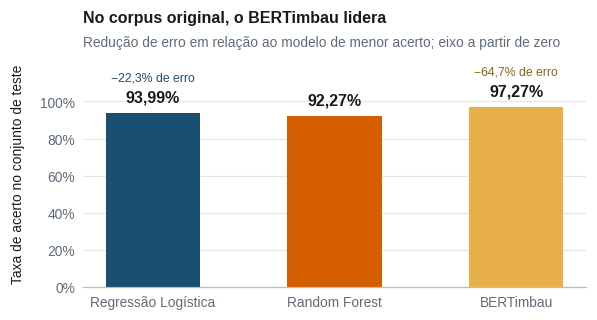

In [8]:
c = pd.read_csv(arquivo('metricas_consolidadas.csv'), index_col=0)
referencia = c['acuracia'].min()

fig, ax = plt.subplots(figsize=(LARGURA, 6.8 * CM))
barras = ax.bar(c.index, c['acuracia'],
                color=[CORES_MODELO[i] for i in c.index], width=0.52)
rotular(ax, barras, fmt='{:.2%}', tam=T_TITULO)


for b, nome in zip(barras, c.index):
    erro_rel = 1 - (1 - c.loc[nome, 'acuracia']) / (1 - referencia)
    if erro_rel > 0.001:
        ax.annotate('−' + pct(erro_rel) + ' de erro',
                    xy=(b.get_x() + b.get_width() / 2, b.get_height()),
                    xytext=(0, 19), textcoords='offset points',
                    ha='center', va='bottom', fontsize=T_PEQUENO,
                    color=legivel(CORES_MODELO[nome]))

escala_percentual(ax, folga_topo=0.22)
grade_y(ax)
ax.set_ylabel('Taxa de acerto no conjunto de teste')
titulo(ax, 'No corpus original, o BERTimbau lidera',
       'Redução de erro em relação ao modelo de menor acerto; eixo a partir '
       'de zero')
salvar(fig, 'fig_desempenho_geral')
plt.show()


## 7. Figura — o custo do descasamento de forma

Esta é a figura central do trabalho. Para cada modelo, três valores: a acurácia no corpus, a detecção em texto natural e a detecção em texto lematizado.

A distância entre a segunda e a terceira barra é o custo de alimentar o modelo com texto numa forma diferente da do treino. A distância entre a primeira e a terceira é a perda de robustez propriamente dita, com as formas casadas. Separar as duas é o que permite dizer qual parte da falha é do modelo e qual é do corpus.

[figura] fig_descasamento.png           15.0 x 8.9 cm  (margem branca completada)


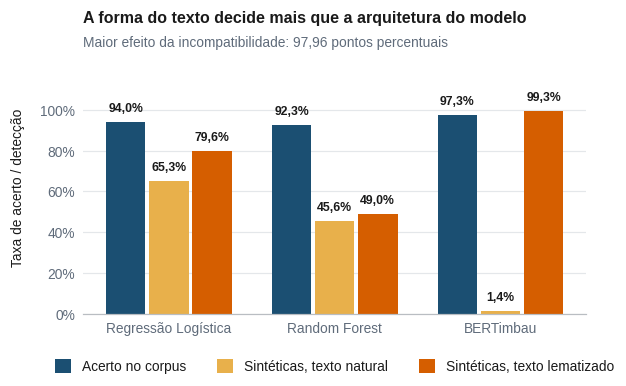

In [9]:
c = pd.read_csv(arquivo('metricas_consolidadas.csv'), index_col=0)

fig, ax = plt.subplots(figsize=(LARGURA, 7.6 * CM))
barras_pareadas(ax, list(c.index),
                [('Acerto no corpus', c['acuracia'].values, AZUL),
                 ('Sintéticas, texto natural',
                  c['deteccao_natural'].values, AMBAR),
                 ('Sintéticas, texto lematizado',
                  c['deteccao_lematizada'].values, LARANJA)],
                fmt='{:.1%}')
escala_percentual(ax, folga_topo=0.24)
ax.set_ylabel('Taxa de acerto / detecção')
legenda_abaixo(ax, ncols=3)

pior = c['custo_descasamento_pp'].abs().max()
titulo(ax, 'A forma do texto decide mais que a arquitetura do modelo',
          'Maior efeito da incompatibilidade: ' + br('{:.2f}'.format(pior))
       + ' pontos percentuais')
salvar(fig, 'fig_descasamento')
plt.show()


## 8. Explicação por LIME

O LIME perturba o texto, observa como a predição muda e ajusta um modelo linear local. Não revela o mecanismo interno do BERTimbau: produz uma aproximação válida na vizinhança daquele texto. A agregação de muitas explicações locais é indício, não demonstração.

A explicação roda sobre o **texto lematizado**. Em texto natural o modelo opera fora da forma em que foi treinado, e explicar essa predição descreveria o descasamento, não o critério de decisão.

In [10]:
EXECUTAR_LIME = True
N_AMOSTRA = 25
N_PERTURBA = 500

if EXECUTAR_LIME:
    !pip install -q lime
    import torch
    from lime.lime_text import LimeTextExplainer
    from transformers import AutoTokenizer, AutoModelForSequenceClassification

    caminho = achar_modelo()
    tok = AutoTokenizer.from_pretrained(caminho)
    modelo = AutoModelForSequenceClassification.from_pretrained(caminho).eval()
    dispositivo = 'cuda' if torch.cuda.is_available() else 'cpu'
    modelo.to(dispositivo)

    @torch.no_grad()
    def probabilidades(textos):
        saida = []
        for i in range(0, len(textos), 64):
            ent = tok([str(t) for t in textos[i:i + 64]], truncation=True,
                      max_length=256, padding=True,
                      return_tensors='pt').to(dispositivo)
            saida.append(torch.softmax(modelo(**ent).logits, dim=-1).cpu().numpy())
        return np.vstack(saida)

    amostra = (pd.Series(lematizado)
               .sample(min(N_AMOSTRA, len(lematizado)), random_state=42)
               .tolist())


    explicador = LimeTextExplainer(class_names=['Verdadeira', 'Falsa'])

    import nltk
    nltk.download('stopwords', quiet=True)
    from nltk.corpus import stopwords
    PARADAS = set(stopwords.words('portuguese'))

    acumulado = {}
    for i, texto in enumerate(amostra, 1):
        exp = explicador.explain_instance(texto, probabilidades,
                                          num_features=20,
                                          num_samples=N_PERTURBA)
        for termo, peso in exp.as_list():
            chave = ' '.join(str(termo).lower().split())
            if chave in PARADAS or len(chave) < 3:
                continue
            acumulado.setdefault(chave, []).append(peso)
        print('  {}/{}'.format(i, len(amostra)), end='\r')

    lime_tab = (pd.DataFrame([{'termo': t, 'peso_medio': np.mean(v),
                               'ocorrencias': len(v)}
                              for t, v in acumulado.items()])
                .query('ocorrencias >= 3')
                .sort_values('peso_medio'))
    lime_tab.to_csv(DADOS / 'lime_termos.csv', index=False)
    print('\n', len(lime_tab), 'termos com ao menos 3 ocorrências')
else:
    lime_tab = pd.read_csv(arquivo('lime_termos.csv'))
print(lime_tab.head(12).to_string(index=False))


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]


 27 termos com ao menos 3 ocorrências
    termo  peso_medio  ocorrencias
  governo   -0.002220            6
    agora   -0.000277            4
    tempo   -0.000168            3
   exigir   -0.000122            4
 garantir   -0.000071            3
    elite   -0.000007            3
   guerra    0.000006            3
população    0.000014            3
     rede    0.000027            3
  urgente    0.000033            9
     povo    0.000047            3
 esconder    0.000047            7


## 9. Figura — termos que pesam na decisão

Peso positivo empurra para "falsa", negativo para "verdadeira". Com as formas casadas, a leitura é sobre o critério que o modelo de fato aprendeu.

[figura] fig_lime_termos.png            15.0 x 12.3 cm  (margem branca completada)


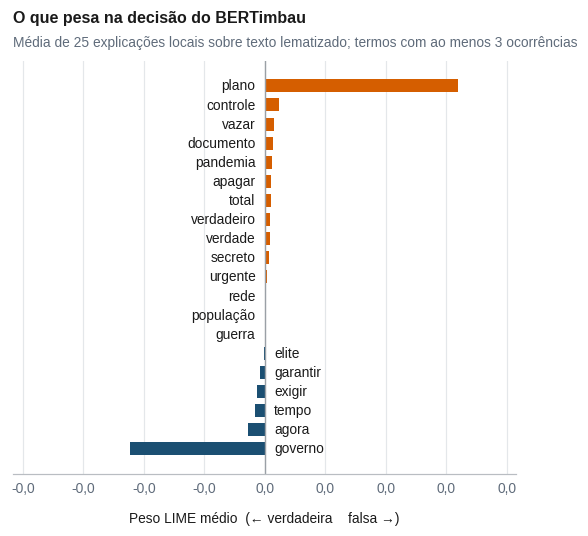

In [11]:
lime_tab = pd.read_csv(arquivo('lime_termos.csv'))
k = min(10, max(len(lime_tab) // 2, 1))
sel = (pd.concat([lime_tab.nsmallest(k, 'peso_medio'),
                  lime_tab.nlargest(k, 'peso_medio')])
       .drop_duplicates(subset='termo')
       .sort_values('peso_medio'))

fig, ax = plt.subplots(figsize=(LARGURA, 0.46 * CM * len(sel) + 3.2 * CM))
cores = [AZUL if v < 0 else LARANJA for v in sel['peso_medio']]
barras = ax.barh(sel['termo'], sel['peso_medio'], color=cores, height=0.68)
for b, t, v in zip(barras, sel['termo'], sel['peso_medio']):
    ax.annotate(t, xy=(0, b.get_y() + b.get_height() / 2),
                xytext=(6 if v < 0 else -6, 0), textcoords='offset points',
                ha='left' if v < 0 else 'right', va='center', fontsize=T_CORPO)
ax.set_yticks([])
ax.axvline(0, color='#9AA0A6', linewidth=0.9)
grade_x(ax)
eixo_decimal(ax, 'x', 1)
ax.spines['bottom'].set_visible(True)
ax.set_xlabel('Peso LIME médio  (← verdadeira    falsa →)')
lim = np.abs(sel['peso_medio']).max() * 1.3
ax.set_xlim(-lim, lim)
titulo(ax, 'O que pesa na decisão do BERTimbau',
       'Média de {} explicações locais sobre texto lematizado; termos com ao '
       'menos 3 ocorrências'.format(N_AMOSTRA if EXECUTAR_LIME else 'várias'))
salvar(fig, 'fig_lime_termos')
plt.show()


## 10. Teste de truncamento

Os textos sintéticos são mais longos que as falsas reais, e comprimento é um atributo que os modelos exploram. Este teste corta cada texto no comprimento mediano das falsas do corpus e repete a avaliação.

O corte é aplicado sobre o texto **lematizado**, para que a única coisa que mude entre as duas medições seja o comprimento. Truncar o texto natural somaria o efeito do comprimento ao do descasamento de forma, e nenhum dos dois ficaria isolado.

In [12]:
EXECUTAR_TRUNCAMENTO = True

if EXECUTAR_TRUNCAMENTO:
    base = pd.read_csv(arquivo('corpus_base.csv'))
    falsas = base.loc[base['classe'] == 'Falsa', 'n_palavras']
    alvo = int(falsas.median())
    print('falsas reais: mediana {} palavras, média {}'
          .format(alvo, br('{:.1f}'.format(falsas.mean()))))

    LIMITES = [30, 45, 61, 80, 100]
    curva = []
    for limite in LIMITES:
        for forma, base_txt in (('natural', natural), ('lematizado', lematizado)):
            cortado = [' '.join(t.split()[:limite]) for t in base_txt]
            taxas = taxas_de_deteccao(cortado)
            taxas.update({'palavras': limite, 'forma': forma})
            curva.append(taxas)
    curva = pd.DataFrame(curva).set_index(['forma', 'palavras'])
    curva.to_csv(DADOS / 'curva_truncamento.csv')
    print('curva de sensibilidade ao comprimento, nas duas formas:')
    print(curva.round(4).to_string())

    fatorial = pd.DataFrame({
        'natural_completo': taxas_de_deteccao(natural),
        'natural_truncado': taxas_de_deteccao(
            [' '.join(t.split()[:alvo]) for t in natural]),
        'lematizado_completo': taxas_de_deteccao(lematizado),
        'lematizado_truncado': taxas_de_deteccao(
            [' '.join(t.split()[:alvo]) for t in lematizado]),
    })
    fatorial['efeito_forma_pp'] = 100 * (fatorial['lematizado_completo']
                                         - fatorial['natural_completo'])
    fatorial['efeito_corte_pp'] = 100 * (fatorial['lematizado_truncado']
                                         - fatorial['lematizado_completo'])
    fatorial.to_csv(DADOS / 'fatorial_forma_comprimento.csv')
    print('\nfatorial 2x2 (forma x comprimento):')
    print(fatorial.round(4).to_string())
    print()

    truncado = [' '.join(t.split()[:alvo]) for t in lematizado]
    antes = float(np.mean([len(t.split()) for t in lematizado]))
    depois = float(np.mean([len(t.split()) for t in truncado]))
    print('sintéticas: {} palavras em média, {} após o truncamento'
          .format(br('{:.1f}'.format(antes)), br('{:.1f}'.format(depois))))

    reducao = 1 - depois / antes
    if reducao < 0.10:
        print('\nATENÇÃO: o truncamento removeu apenas {} das palavras. Com '
              'um corte desse tamanho o teste não distingue comprimento de '
              'conteúdo. Confira se `alvo` saiu mesmo da classe falsa.'
              .format(pct(reducao)))

    trunc = pd.DataFrame({'completo': taxas_de_deteccao(lematizado),
                          'truncado': taxas_de_deteccao(truncado)})
    trunc['diferenca_pp'] = 100 * (trunc['truncado'] - trunc['completo'])
    trunc.to_csv(DADOS / 'truncamento.csv')
    print()
    print(trunc.round(4).to_string())
else:
    trunc = pd.read_csv(arquivo('truncamento.csv'), index_col=0)


falsas reais: mediana 61 palavras, média 68,6
curva de sensibilidade ao comprimento, nas duas formas:
                     Regressão Logística  Random Forest  BERTimbau
forma      palavras                                               
natural    30                     0.9184         0.8844     0.3741
lematizado 30                     0.9728         0.9252     0.9796
natural    45                     0.8503         0.7687     0.1293
lematizado 45                     0.9320         0.8231     1.0000
natural    61                     0.7823         0.6327     0.0680
lematizado 61                     0.8639         0.6871     1.0000
natural    80                     0.7347         0.5170     0.0272
lematizado 80                     0.8027         0.5918     1.0000
natural    100                    0.6667         0.4762     0.0204
lematizado 100                    0.8027         0.5034     1.0000

fatorial 2x2 (forma x comprimento):
                     natural_completo  natural_truncado  

## 11. Figura — sensibilidade ao comprimento

A curva percorre cinco limites de corte. Se a detecção subir de forma ordenada à medida que o texto encurta, o comprimento está associado à predição; se oscilar, o corte único em 61 palavras teria sido coincidência. O truncamento remove palavras junto com o comprimento, de modo que a leitura é de associação, não de causa isolada.

[figura] fig_curva_truncamento.png      15.0 x 9.3 cm  (margem branca completada)


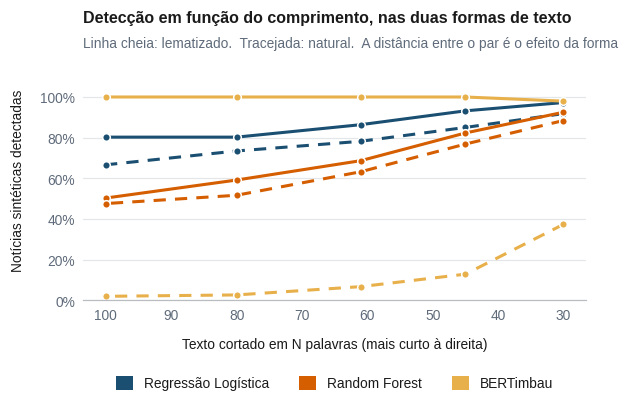

In [13]:
curva = pd.read_csv(arquivo('curva_truncamento.csv'), index_col=[0, 1])
ordem = [c for c in ['Regressão Logística', 'Random Forest', 'BERTimbau']
         if c in curva.columns]
fig, ax = plt.subplots(figsize=(LARGURA, 7.2 * CM))
for nome in ordem:
    for forma, estilo in (('lematizado', '-'), ('natural', (0, (4, 3)))):
        if forma not in curva.index.get_level_values(0):
            continue
        serie = curva.xs(forma, level=0)[nome].sort_index()
        ax.plot(serie.index, serie.values, linestyle=estilo, marker='o',
                color=CORES_MODELO[nome], linewidth=2.0, markersize=5,
                markeredgecolor='white', markeredgewidth=1.0)
ax.invert_xaxis()
grade_y(ax)
escala_percentual(ax, folga_topo=0.18)
ax.set_xlabel('Texto cortado em N palavras (mais curto à direita)')
ax.set_ylabel('Notícias sintéticas detectadas')
legenda_manual(ax, [(n, CORES_MODELO[n]) for n in ordem], ncols=3)
titulo(ax, 'Detecção em função do comprimento, nas duas formas de texto',
       'Linha cheia: lematizado.  Tracejada: natural.  A distância entre o '
       'par é o efeito da forma')
salvar(fig, 'fig_curva_truncamento')
plt.show()


## 12. Figura — efeito do truncamento

[figura] fig_truncamento.png            15.0 x 9.0 cm  (margem branca completada)


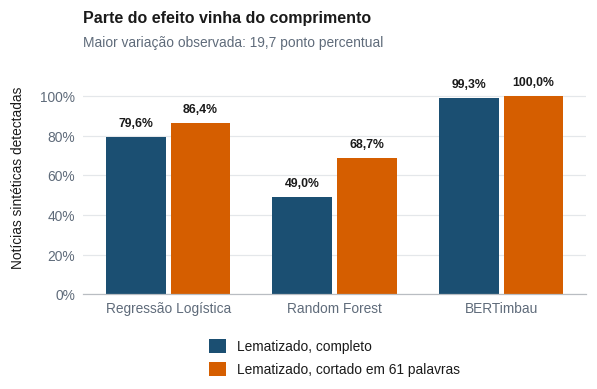

In [14]:
trunc = pd.read_csv(arquivo('truncamento.csv'), index_col=0)
trunc = trunc.reindex([i for i in ['Regressão Logística', 'Random Forest',
                                   'BERTimbau'] if i in trunc.index])

fig, ax = plt.subplots(figsize=(LARGURA, 7.0 * CM))
barras_pareadas(ax, list(trunc.index),
                [('Lematizado, completo', trunc['completo'].values, AZUL),
                 ('Lematizado, cortado em {} palavras'.format(alvo),
                  trunc['truncado'].values, LARANJA)],
                fmt='{:.1%}')
escala_percentual(ax, folga_topo=0.18)
ax.set_ylabel('Notícias sintéticas detectadas')
legenda_abaixo(ax, ncols=1)

maior = trunc['diferenca_pp'].abs().max()
titulo(ax, 'Igualar o comprimento muda pouco a detecção'
       if maior < 5 else 'Parte do efeito vinha do comprimento',
       'Maior variação observada: ' + br('{:.1f}'.format(maior))
       + ' ponto percentual')
salvar(fig, 'fig_truncamento')
plt.show()
